# Parsing forecast data



In [1]:
import pandas as pd  # library for data analysis
import matplotlib.pyplot as plt  # library for plotting
import numpy as np  # library for math and linear algebra

## File naming convention

The forecasting files can be found in this GitHub repository: https://github.com/AdamRJensen/solar-resource-course-2026/tree/main/forecast-data

The files are named according to the station and the time of when the forecast was retrieved. For example, the file ``06031_20261109T1800.csv`` is a forecast retrieved on 2026-11-09 at 18:00 UTC for the DMI station 06031.

The function below can be used to convenietly parse the forecast data into a pandas DataFrame.

The returned DataFrame has a multi-index for the row. The reason for this is that a given timestamp occurs multiple times. For example, the irradiance for noon tomorrow is included in the forecast today, but also included in the forecast made in the early hours of tomorrow. The differentiation between the two forecast values for the same timestamp is that they were made at different times. This is described by the forecast lead time, which is the number between the forecasted timestamp and when the forecast was made. For example, if we use a forecast made today at noon and consider the forecast value for tomorro at noon, there is 24 hours difference and the lead time is therefore 24 hours.

In [48]:
URL = "https://raw.githubusercontent.com/AdamRJensen/solar-resource-course-2026/refs/heads/main/forecast-data/"
from urllib.error import HTTPError

def get_forecast_data(station, start, end, url=URL):
    start = pd.Timestamp(start)
    end = pd.Timestamp(end)
    if start.tzinfo is None:
        start = start.tz_localize('UTC')
    else:
        start = start.tz_convert('UTC')
    if end.tzinfo is None:
        end = end.tz_localize('UTC')
    else:
        end = end.tz_convert('UTC')

    times = pd.date_range(start, end, freq='1h')

    dfs = []
    for t in times:
        filename = f"{station}_{t.strftime('%Y%m%dT%H%M')}.csv"
        try:
            dfi = pd.read_csv(url + filename, index_col=0, parse_dates=[0])
            dfi = dfi[dfi.index >= t]  # drop rows with timestamps before the forecast time
            lead_time = (dfi.index - t).total_seconds() / (60*60)
            dfi.index = [dfi.index, lead_time]
            dfs.append(dfi)
        except HTTPError:
            print(f"File not found: {filename}")
    if dfs:
        return pd.concat(dfs)
    else:
        raise FileNotFoundError("No forecast data files found.")


In [49]:
data = get_forecast_data(station="06031", start="2026-11-09", end="2026-11-11")

File not found: 06031_20261109T0000.csv
File not found: 06031_20261109T0100.csv
File not found: 06031_20261109T0200.csv
File not found: 06031_20261109T0300.csv
File not found: 06031_20261109T0400.csv
File not found: 06031_20261109T0500.csv
File not found: 06031_20261109T0600.csv
File not found: 06031_20261109T1900.csv
File not found: 06031_20261109T2000.csv
File not found: 06031_20261109T2100.csv
File not found: 06031_20261109T2200.csv
File not found: 06031_20261109T2300.csv
File not found: 06031_20261110T0000.csv
File not found: 06031_20261110T0100.csv
File not found: 06031_20261110T0200.csv
File not found: 06031_20261110T0300.csv
File not found: 06031_20261110T0400.csv
File not found: 06031_20261110T0500.csv
File not found: 06031_20261110T0600.csv
File not found: 06031_20261110T0700.csv
File not found: 06031_20261110T0800.csv
File not found: 06031_20261110T0900.csv
File not found: 06031_20261110T1000.csv
File not found: 06031_20261110T1100.csv
File not found: 06031_20261110T1200.csv


In [39]:
data

,,dmi_harmonie_arome_europe,metno_nordic,ecmwf_ifs025,ecmwf_aifs025_single,gfs_global,ecmwf_ifs,dmi_seamless,gfs_seamless
date,date,,,,,,,,
2026-11-09 07:00:00+00:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2026-11-09 08:00:00+00:00,1.0,8.0,14.0,25.0,24.0,6.0,25.0,8.0,6.0
2026-11-09 09:00:00+00:00,2.0,33.0,37.0,71.0,60.0,20.0,89.0,33.0,20.0
2026-11-09 10:00:00+00:00,3.0,135.0,49.0,114.0,86.0,34.0,102.0,135.0,34.0
2026-11-09 11:00:00+00:00,4.0,220.0,80.0,143.0,100.0,46.0,97.0,220.0,46.0
...,...,...,...,...,...,...,...,...,...
2026-11-15 19:00:00+00:00,145.0,NaN,NaN,0.0,0.0,0.0,0.0,0.0,0.0
2026-11-15 20:00:00+00:00,146.0,NaN,NaN,0.0,0.0,0.0,0.0,0.0,0.0
2026-11-15 21:00:00+00:00,147.0,NaN,NaN,0.0,0.0,0.0,0.0,0.0,0.0


## Example plot

In the code cell above, you'll notice that the DataFrame has 8 columns which correspond to the different forecast models. One example of a forecast model is ``metno_nordic``.

It is easiest to work with one forecast model at a time. To avoid having the rows be specified by a multi-index, we can use ``.unstack()`` function, to unstack the index, such that the index becomes just the time and the lead time becomes the columns.

In [51]:
data["dmi_harmonie_arome_europe"].unstack()

date,0.0,1.0,2.0,3.0,4.0,5.0,6.0,7.0,8.0,9.0,...,151.0,152.0,153.0,154.0,155.0,156.0,157.0,158.0,159.0,160.0
date,,,,,,,,,,,,,,,,,,,,,
2026-11-09 07:00:00+00:00,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2026-11-09 08:00:00+00:00,8.0,8.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2026-11-09 09:00:00+00:00,33.0,33.0,33.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2026-11-09 10:00:00+00:00,122.0,135.0,135.0,135.0,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2026-11-09 11:00:00+00:00,139.0,139.0,220.0,220.0,220.0,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2026-11-15 19:00:00+00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2026-11-15 20:00:00+00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2026-11-15 21:00:00+00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


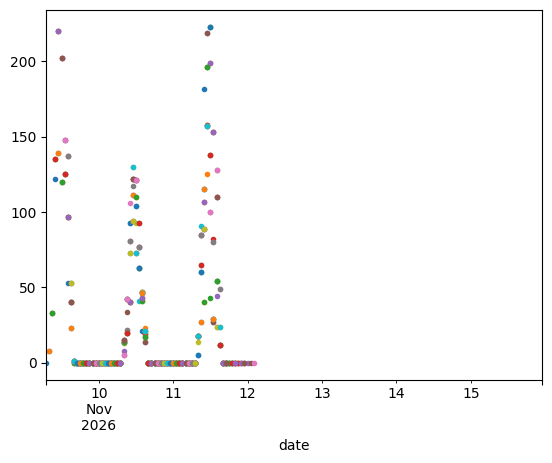

In [52]:
fig, ax = plt.subplots()
data["dmi_harmonie_arome_europe"].unstack().plot(ax=ax, lw=0, marker=".")
plt.legend().remove()
plt.show()